In [2]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parents[0]
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)
from modules.features import HolisticLandmarksFeatureExtracter, FeatureTransformer
from modules.image_annotators import RealLifeTestAnnotator
from modules.model_factory import (SimpleModel,
                                  SimpleModelWithNoise,
                                  SimpleLSTMModel)
from modules.features.transformations import (FeatureWeights, 
                                              FeatureCentering,
                                              FeatureNormalizer,
                                              FeatureRemoveLegData,
                                              FeatureRemoveZCoordinates)

from modules.utilities import load_dataset, transform_dataset, transform_datasets
from modules.process import train_and_validate_model

In [3]:
DATA_PATH: Path = PROJECT_ROOT / 'mp_data'
DATA_PATH_VALIDATION: Path = PROJECT_ROOT / 'mp_data_validation'
DATA_PATH_TEST: Path = PROJECT_ROOT / 'mp_data_new_test'

# TODO: record test data
TEST_DATA_PATH: Path = PROJECT_ROOT / 'mp_data_new_test'
TENSORFLOW_MODEL_PATH: Path = Path('./output_models/simple_model.keras')
NR_OF_EPOCHS: int = 50

feature_extracter = HolisticLandmarksFeatureExtracter()

feature_transformer_none = FeatureTransformer()
feature_transformer_normalized = FeatureTransformer([FeatureNormalizer()])
feature_transformer_weighted = FeatureTransformer([FeatureWeights(10.0, 10.0, 2.0, 0.5)])
feature_transformer_centered = FeatureTransformer([FeatureCentering()])
feature_transformer_no_z_index = FeatureTransformer([FeatureRemoveZCoordinates()])
feature_transformer_leg_removal = FeatureTransformer([FeatureRemoveLegData()])
feature_transformer_all = FeatureTransformer([FeatureRemoveLegData(), FeatureRemoveZCoordinates(), FeatureNormalizer(), FeatureCentering(), FeatureWeights(10.0, 10.0, 2.0, 0.5)])

model_factory = SimpleModel()

In [4]:
# load data
raw_data, labels, actions = load_dataset(DATA_PATH, 
                                             feature_extracter=feature_extracter)

raw_validation, validation_labels, actions_validation = load_dataset(DATA_PATH_VALIDATION,
                                                feature_extracter=feature_extracter)

normalized_data, normalized_validation = transform_datasets(datasets=[raw_data, raw_validation], feature_transformer=feature_transformer_normalized)
weighted_data, weighted_validation = transform_datasets(datasets=[raw_data, raw_validation], feature_transformer=feature_transformer_weighted)
centered_data, centered_validation = transform_datasets(datasets=[raw_data, raw_validation], feature_transformer=feature_transformer_centered)
no_z_index_data, no_z_index_validation = transform_datasets(datasets=[raw_data, raw_validation], feature_transformer=feature_transformer_no_z_index)
no_leg_data, no_leg_validation = transform_datasets(datasets=[raw_data, raw_validation], feature_transformer=feature_transformer_leg_removal)

all_transformations_data, all_transformations_validation = transform_datasets(datasets=[raw_data, raw_validation], feature_transformer=feature_transformer_all)

In [5]:
baseline_model, baseline_training = train_and_validate_model(model_factory=model_factory,
                         actions=actions,
                         train_dataset=raw_data,
                         train_labels=labels,
                         validation_dataset=raw_validation,
                         validation_labels=validation_labels,
                         nr_of_epochs=NR_OF_EPOCHS)

normalized_model, normalized_training = train_and_validate_model(model_factory=model_factory,
                            actions=actions,
                            train_dataset=normalized_data,
                            train_labels=labels,
                            validation_dataset=normalized_validation,
                            validation_labels=validation_labels,
                            nr_of_epochs=NR_OF_EPOCHS)

weighted_model, weighted_training = train_and_validate_model(model_factory=model_factory,
                            actions=actions,
                            train_dataset=weighted_data,
                            train_labels=labels,
                            validation_dataset=weighted_validation,
                            validation_labels=validation_labels,
                            nr_of_epochs=NR_OF_EPOCHS)

centered_model, centered_training = train_and_validate_model(model_factory=model_factory,
                            actions=actions,
                            train_dataset=centered_data,
                            train_labels=labels,
                            validation_dataset=centered_validation,
                            validation_labels=validation_labels,
                            nr_of_epochs=NR_OF_EPOCHS)

no_z_index_model, no_z_index_training = train_and_validate_model(model_factory=model_factory,
                            actions=actions,
                            train_dataset=no_z_index_data,
                            train_labels=labels,
                            validation_dataset=no_z_index_validation,
                            validation_labels=validation_labels,
                            nr_of_epochs=NR_OF_EPOCHS)

no_leg_model, no_leg_training = train_and_validate_model(model_factory=model_factory,
                            actions=actions,
                            train_dataset=no_leg_data,
                            train_labels=labels,
                            validation_dataset=no_leg_validation,
                            validation_labels=validation_labels,
                            nr_of_epochs=NR_OF_EPOCHS)

all_transformations_model, all_transformations_training = train_and_validate_model(model_factory=model_factory,
                            actions=actions,
                            train_dataset=all_transformations_data,
                            train_labels=labels,
                            validation_dataset=all_transformations_validation,
                            validation_labels=validation_labels,
                            nr_of_epochs=NR_OF_EPOCHS)


Actions: ['idle', 'poes', 'slapen', 'vogel']
Number of sequences: 120
Number of classes: 4
Input shape: (120, 30, 1659)
Input dtype: float32
NaN values: 0
Infinite values: 0
Epoch 1/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 158ms/step - categorical_accuracy: 0.2083 - loss: 1.5050 - val_categorical_accuracy: 0.2500 - val_loss: 1.3994
Epoch 2/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - categorical_accuracy: 0.2250 - loss: 1.4216 - val_categorical_accuracy: 0.4250 - val_loss: 1.3674
Epoch 3/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - categorical_accuracy: 0.1833 - loss: 1.4719 - val_categorical_accuracy: 0.5167 - val_loss: 1.3549
Epoch 4/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - categorical_accuracy: 0.2417 - loss: 1.3922 - val_categorical_accuracy: 0.2500 - val_loss: 1.3564
Epoch 5/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - categorical_accuracy: 0.3167 - loss: 1.3592 - val_categorical_accuracy: 0.2500 - val_loss: 1.3055
Epoch 6/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - categorical_accuracy: 0.3500 

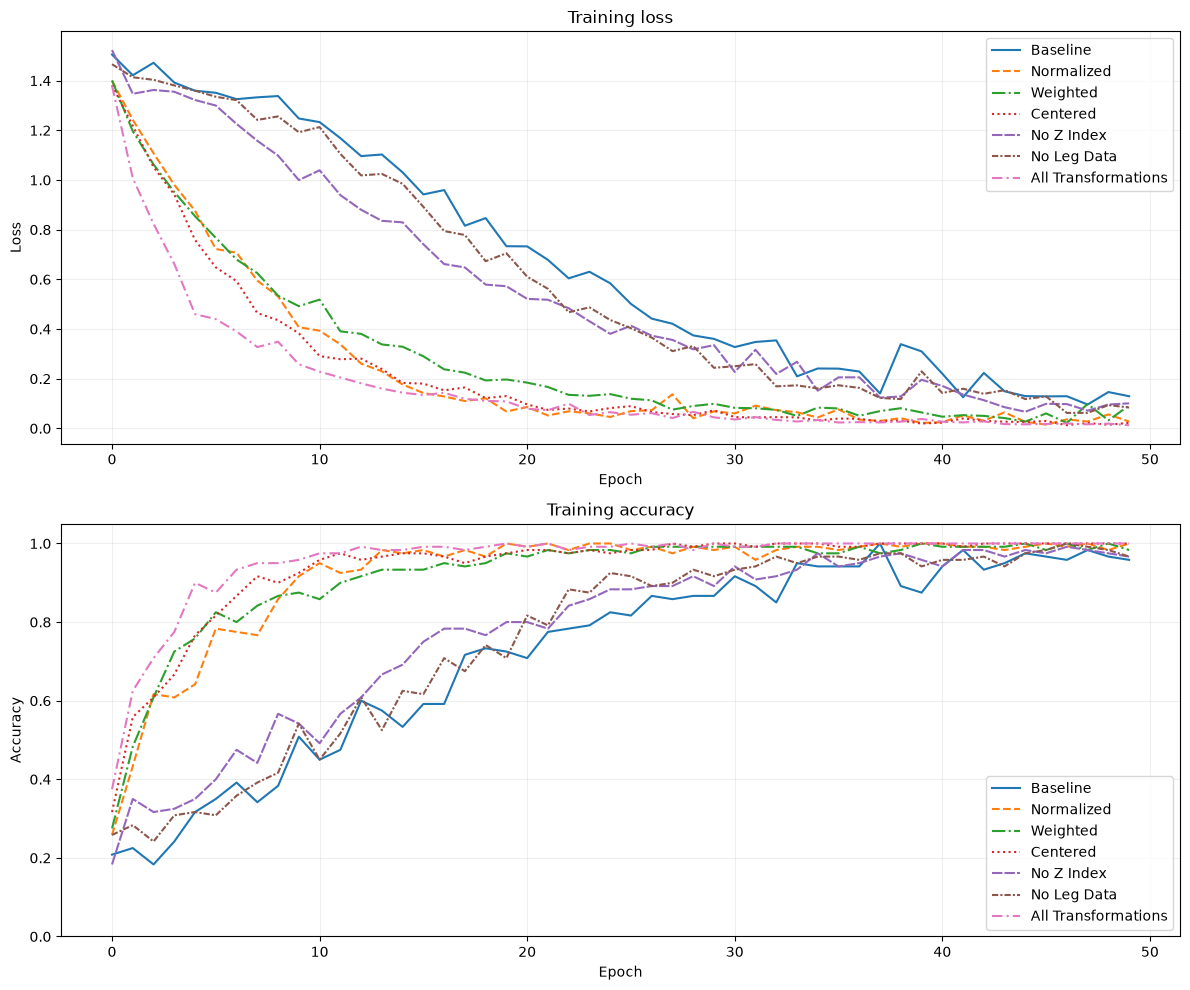

In [10]:
linestyles = ["-", "--", "-.", ":", (0, (5, 1)), (0, (3, 1, 1, 1)), (0, (5, 2, 1, 2))]

fig, axes = plt.subplots(2, 1, figsize=(12, 10))

for (label, history), linestyle in zip(
    [
        ("Baseline", baseline_training),
        ("Normalized", normalized_training),
        ("Weighted", weighted_training),
        ("Centered", centered_training),
        ("No Z Index", no_z_index_training),
        ("No Leg Data", no_leg_training),
        ("All Transformations", all_transformations_training)
    ],
    linestyles
):
    axes[0].plot(history.history["loss"], label=label, linestyle=linestyle)
    axes[1].plot(history.history["categorical_accuracy"], label=label, linestyle=linestyle)

axes[0].set(title="Training loss", xlabel="Epoch", ylabel="Loss")
axes[1].set(title="Training accuracy", xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1.05))

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [7]:
# def predictions(model, x):
#     return np.argmax(model.predict(x, verbose=0), axis=1)

# # Apply all transformations
# test_transformed = transform_dataset(
#     raw_data,
#     feature_transformer=feature_transformer_all
# )

# # Compare baseline against all transformations
# original_base_pred = predictions(baseline_model, raw_data)
# original_all_pred = predictions(all_transformations_model, test_transformed)

# original_results = {
#     "Baseline": accuracy_score(labels, original_base_pred),
#     "All Transformations": accuracy_score(labels, original_all_pred),
# }

# print("Original test set (n=%d):" % len(labels), original_results)

# print(
#     "Difference in percentage points:",
#     round(
#         100 * (original_results["All Transformations"] - original_results["Baseline"]),
#         2
#     )
# )

In [ ]:
# 1. Load independent test data
test_raw, test_labels, test_actions = load_dataset(
    DATA_PATH_TEST,
    feature_extracter=feature_extracter
)

# Ensure class indices have the same meaning for both datasets
assert list(test_actions) == list(actions), (
    f"Class mismatch: training={actions}, test={test_actions}"
)

# 2. Apply all transformations
test_all = transform_dataset(
    test_raw,
    feature_transformer=feature_transformer_all
)

# 3. Prediction helper
def predictions(model, x):
    return np.argmax(model.predict(x, verbose=0), axis=1)

def class_indices(y):
    y = np.asarray(y)
    return np.argmax(y, axis=1) if y.ndim > 1 and y.shape[-1] > 1 else y.reshape(-1)

y_true = class_indices(test_labels)

# 4. Evaluate both models on exactly the same recordings
model_inputs = {
    "Baseline": (baseline_model, test_raw),
    "All Transformations": (all_transformations_model, test_all)
}

results = {}
predictions_by_model = {}
confusion_matrices = {}

for name, (model, x) in model_inputs.items():
    y_pred = predictions(model, x)
    predictions_by_model[name] = y_pred

    confusion_matrices[name] = confusion_matrix(
        y_true, y_pred,
        labels=np.arange(len(actions))
    )

    results[name] = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
        "Macro F1": classification_report(
            y_true, y_pred,
            labels=np.arange(len(actions)),
            target_names=actions,
            output_dict=True,
            zero_division=0
        )["macro avg"]["f1-score"]
    }

    print(f"\n{'=' * 50}")
    print(name)
    print(f"{'=' * 50}")

    print(classification_report(
        y_true,
        y_pred,
        labels=np.arange(len(actions)),
        target_names=actions,
        zero_division=0
    ))

    print("Confusion matrix:")
    print(confusion_matrix(
        y_true, y_pred,
        labels=np.arange(len(actions))
    ))

# 5. Overall comparison
print("\nOverall comparison")
print(f"Test samples: {len(y_true)}")

for metric in ["Accuracy", "Balanced accuracy", "Macro F1"]:
    baseline = results["Baseline"][metric]
    transformed = results["All Transformations"][metric]

    print(
        f"{metric:20s}: "
        f"Baseline={baseline:.3f}, "
        f"All transformations={transformed:.3f}, "
        f"Difference={(transformed - baseline) * 100:+.2f} pp"
    )



Baseline
              precision    recall  f1-score   support

        idle       0.31      0.27      0.29        30
        poes       0.61      0.47      0.53        30
      slapen       0.61      0.47      0.53        30
       vogel       0.48      0.77      0.59        30

    accuracy                           0.49       120
   macro avg       0.50      0.49      0.48       120
weighted avg       0.50      0.49      0.48       120

Confusion matrix:
[[ 8  2  2 18]
 [ 9 14  3  4]
 [ 7  6 14  3]
 [ 2  1  4 23]]

All Transformations
              precision    recall  f1-score   support

        idle       0.59      0.67      0.62        30
        poes       0.91      0.70      0.79        30
      slapen       0.65      0.73      0.69        30
       vogel       0.76      0.73      0.75        30

    accuracy                           0.71       120
   macro avg       0.73      0.71      0.71       120
weighted avg       0.73      0.71      0.71       120

Confusion matrix:
[[

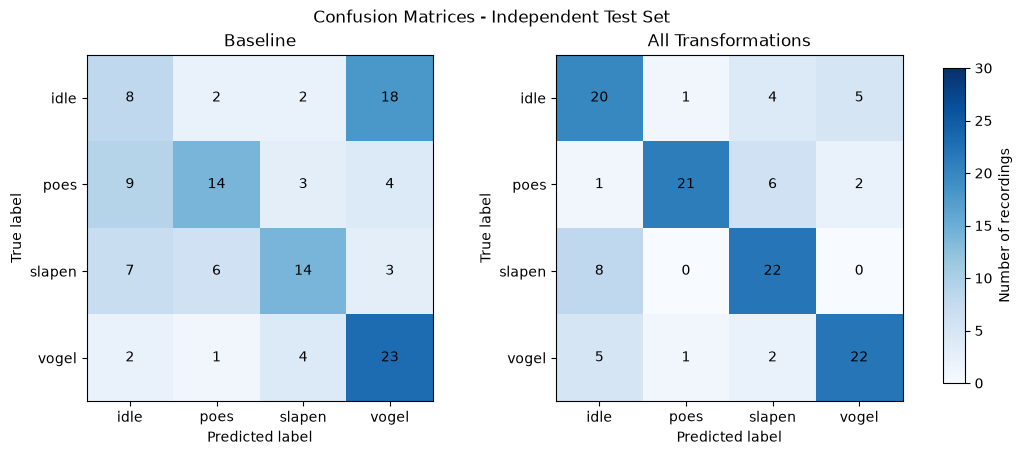

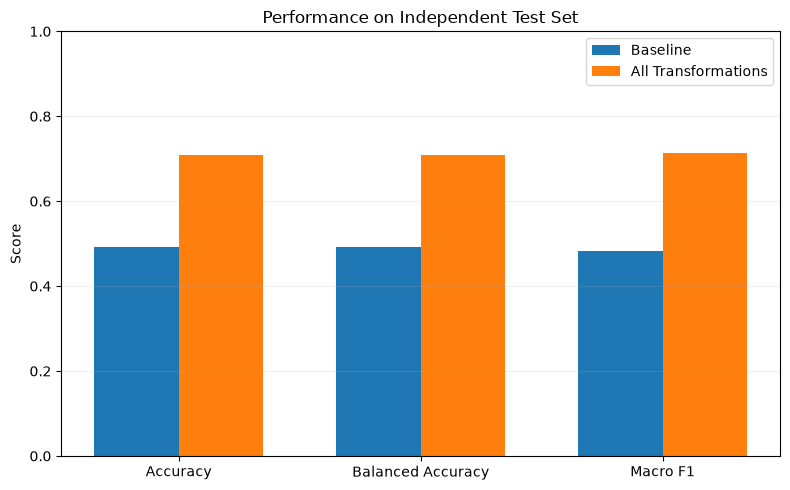

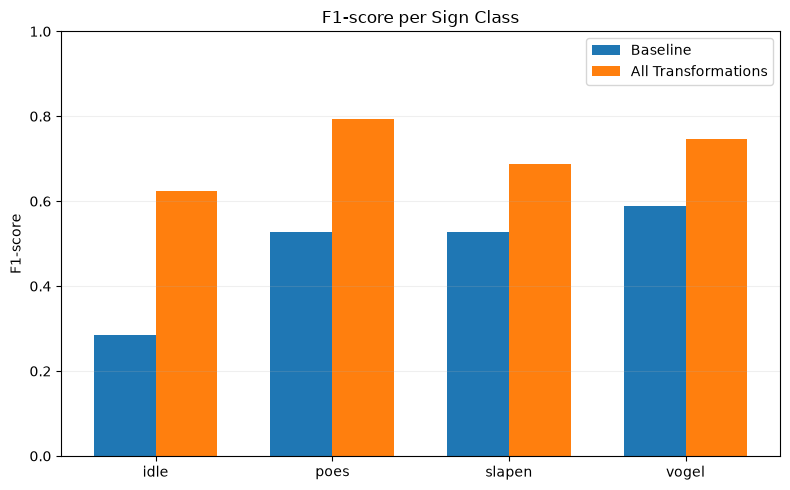

Performance comparison
Accuracy            : Baseline=0.492, All Transformations=0.708, Difference=+21.67 pp
Balanced Accuracy   : Baseline=0.492, All Transformations=0.708, Difference=+21.67 pp
Macro F1            : Baseline=0.483, All Transformations=0.713, Difference=+22.97 pp


In [ ]:
x# Plot confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, name in zip(
    axes,
    ["Baseline", "All Transformations"]
):
    cm = confusion_matrices[name]

    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=30)

    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_xticks(range(len(actions)), actions)
    ax.set_yticks(range(len(actions)), actions)

    for i in range(len(actions)):
        for j in range(len(actions)):
            ax.text(j, i, cm[i, j], ha="center", va="center")

fig.subplots_adjust(right=0.88, wspace=0.3)
cbar_ax = fig.add_axes([0.91, 0.15, 0.02, 0.7])
fig.colorbar(im, cax=cbar_ax, label="Number of recordings")

fig.suptitle("Confusion Matrices - Independent Test Set")
plt.show()


# Compare overall performance
metrics = ["Accuracy", "Balanced accuracy", "Macro F1"]

baseline_scores = [results["Baseline"][m] for m in metrics]
combined_scores = [results["All Transformations"][m] for m in metrics]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(x - width/2, baseline_scores, width, label="Baseline")
ax.bar(x + width/2, combined_scores, width, label="All Transformations")

ax.set_ylabel("Score")
ax.set_title("Performance on Independent Test Set")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


# Compare F1-score per sign class
baseline_report = classification_report(
    y_true,
    predictions_by_model["Baseline"],
    labels=np.arange(len(actions)),
    target_names=actions,
    output_dict=True,
    zero_division=0
)

combined_report = classification_report(
    y_true,
    predictions_by_model["All Transformations"],
    labels=np.arange(len(actions)),
    target_names=actions,
    output_dict=True,
    zero_division=0
)

baseline_f1 = [baseline_report[c]["f1-score"] for c in actions]
combined_f1 = [combined_report[c]["f1-score"] for c in actions]

x = np.arange(len(actions))

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(x - width/2, baseline_f1, width, label="Baseline")
ax.bar(x + width/2, combined_f1, width, label="All Transformations")

ax.set_ylabel("F1-score")
ax.set_title("F1-score per Sign Class")
ax.set_xticks(x)
ax.set_xticklabels(actions)
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()